In [6]:
!pip install pyfixest[jax]

In [7]:
!pip install linearmodels

In [8]:
import pandas as pd
import statsmodels.formula.api as smf
import seaborn as sns
import matplotlib.pyplot as plt
from pyfixest.estimation import feols
import scipy.stats
import numpy as np
from matplotlib.lines import Line2D
import linearmodels as lm



from google.colab import drive
drive.mount('/content/gdrive')

attendance_df = pd.read_csv(r'/content/gdrive/My Drive/ECON 692/WNBA All Game Attendance - All Game Attendance.csv')

Drive already mounted at /content/gdrive; to attempt to forcibly remount, call drive.mount("/content/gdrive", force_remount=True).


In [9]:
attendance_df.head()

,Unnamed: 0,Year,Day of Week,Month,Day,Time (ET),Game Type,Home Team,Away Team,Arena,City,State,Attendance
0,1,1997,Saturday,June,21,4:00 PM,Regular season,Los Angeles Sparks,New York Liberty,Great Western Forum,Los Angeles,CA,14284
1,2,1997,Saturday,June,21,7:00 PM,Regular season,Cleveland Rockers,Houston Comets,Quicken Loans Arena,Cleveland,OH,11455
2,3,1997,Saturday,June,21,5:00 AM,Regular season,Utah Starzz,Sacramento Monarchs,EnergySolutions Arena,Salt Lake City,UT,8915
3,4,1997,Sunday,June,22,4:00 PM,Regular season,Phoenix Mercury,Charlotte Sting,US Airways Center,Phoenix,AZ,16102
4,5,1997,Monday,June,23,3:00 AM,Regular season,Utah Starzz,Los Angeles Sparks,EnergySolutions Arena,Salt Lake City,UT,8036


                          PanelOLS Estimation Summary                           
Dep. Variable:             Attendance   R-squared:                        0.0071
Estimator:                   PanelOLS   R-squared (Between):             -0.0146
No. Observations:                6214   R-squared (Within):               0.0055
Date:                Thu, Apr 10 2025   R-squared (Overall):             -0.0062
Time:                        02:43:38   Log-likelihood                -5.787e+04
Cov. Estimator:             Clustered                                           
                                        F-statistic:                      7.3535
Entities:                          29   P-value                           0.0000
Avg Obs:                       214.28   Distribution:                  F(6,6153)
Min Obs:                       1.0000                                           
Max Obs:                       503.00   F-statistic (robust):             125.47
                            

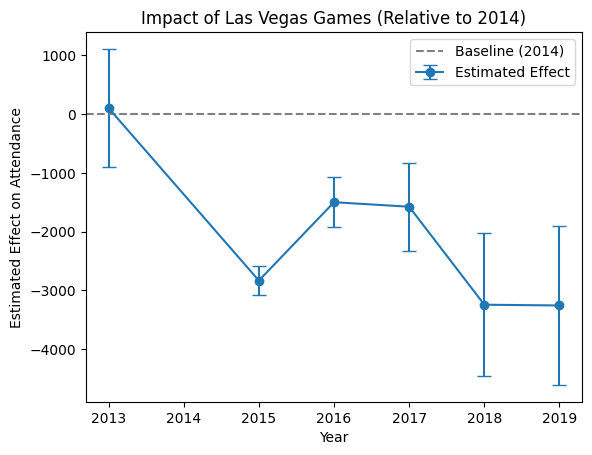

In [53]:
# Las Vegas Aces (Kayla McBride; 2014-2020)
former_aces = ["Utah Starzz", "San Antonio Silver Stars", "San Antonio Stars", "Las Vegas Aces"]
lv_attendance_df = attendance_df.copy()

# 🚀 2. Create Treatment Variable for Aces Games (2014-2020)
lv_attendance_df['LV_Aces_Game'] = (
    lv_attendance_df['Home Team'].isin(former_aces) & lv_attendance_df['Year'].between(2013, 2020)
)

# 🚀 3. Create Interaction Terms for Each Year (Skip 2014 as the Reference; no data for 2020 (COVID year) so I will also omit it)
for year in [2013, 2015, 2016, 2017, 2018, 2019]:
    col_name = f'INX{year}'
    lv_attendance_df[col_name] = lv_attendance_df['LV_Aces_Game'].astype(int)
    lv_attendance_df.loc[lv_attendance_df['Year'] != year, col_name] = 0

# 🚀 4. Set Index for Panel Data (Team and Year)
lv_attendance_df = lv_attendance_df.set_index(['Home Team', 'Year'])

# 🚀 5. Define and Fit Panel Regression Model
mod = lm.PanelOLS.from_formula(
    'Attendance ~ INX2013 + INX2015 + INX2016 + INX2017 + INX2018 + INX2019 + EntityEffects + TimeEffects - TimeEffects[2014]',
    lv_attendance_df
)
clfe = mod.fit(cov_type='clustered', cluster_entity=True)
print(clfe.summary)

# 🚀 6. Extract Coefficients and Confidence Intervals
res = pd.concat([clfe.params, clfe.std_errors], axis=1)
res.columns = ['parameter', 'std_error']
res['ci'] = res['std_error'] * 1.96  # 95% CI
res['Year'] = [2013, 2015, 2016, 2017, 2018, 2019]  # Excluding 2014 as the reference

# Print results table
print("\n📊 Coefficients & Confidence Intervals:")
print(res)

# 🚀 7. Plot the Results
plt.errorbar(x=res['Year'], y=res['parameter'], yerr=res['ci'], fmt='o-', capsize=5, label="Estimated Effect")
plt.axhline(0, linestyle='dashed', color='gray', label="Baseline (2014)")
plt.xlabel("Year")
plt.ylabel("Estimated Effect on Attendance")
plt.title("Impact of Las Vegas Games (Relative to 2014)")
plt.legend()
plt.show()


                          PanelOLS Estimation Summary                           
Dep. Variable:             Attendance   R-squared:                        0.0077
Estimator:                   PanelOLS   R-squared (Between):              0.0017
No. Observations:                6214   R-squared (Within):               0.0067
Date:                Thu, Apr 10 2025   R-squared (Overall):              0.0025
Time:                        02:43:53   Log-likelihood                -5.852e+04
Cov. Estimator:             Clustered                                           
                                        F-statistic:                      6.8702
Entities:                          29   P-value                           0.0000
Avg Obs:                       214.28   Distribution:                  F(7,6180)
Min Obs:                       1.0000                                           
Max Obs:                       503.00   F-statistic (robust):             98.516
                            

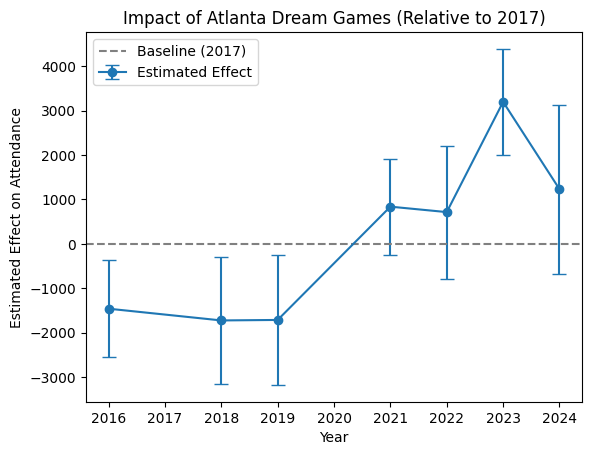

In [55]:
# Las Vegas Aces (Kelsey Plum; 2017-2024)
former_aces = ["Utah Starzz", "San Antonio Silver Stars", "San Antonio Stars", "Las Vegas Aces"]
lv_attendance_df = attendance_df.copy()

# 🚀 2. Create Treatment Variable for Aces Games (2017-2024)
lv_attendance_df['LV_Aces_Game'] = (
    lv_attendance_df['Home Team'].isin(former_aces) & lv_attendance_df['Year'].between(2016, 2024)
)

# 🚀 3. Create Interaction Terms for Each Year (Skip 2017 as the Reference; no data for 2020 (COVID year) so I will also omit it)
for year in [2016, 2018, 2019, 2021, 2022, 2023, 2024]:
    col_name = f'INX{year}'
    lv_attendance_df[col_name] = lv_attendance_df['LV_Aces_Game'].astype(int)
    lv_attendance_df.loc[lv_attendance_df['Year'] != year, col_name] = 0

# 🚀 4. Set Index for Panel Data (Team and Year)
lv_attendance_df = lv_attendance_df.set_index(['Home Team', 'Year'])

# 🚀 5. Define and Fit Panel Regression Model
mod = lm.PanelOLS.from_formula(
    'Attendance ~ INX2016 + INX2018 + INX2019 + INX2021 + INX2022 + INX2023 + INX2024 + TimeEffects - TimeEffects[2017]',
    lv_attendance_df
)
clfe = mod.fit(cov_type='clustered', cluster_entity=True)
print(clfe.summary)

# 🚀 6. Extract Coefficients and Confidence Intervals
res = pd.concat([clfe.params, clfe.std_errors], axis=1)
res.columns = ['parameter', 'std_error']
res['ci'] = res['std_error'] * 1.96  # 95% CI
res['Year'] = [2016, 2018, 2019, 2021, 2022, 2023, 2024]  # Excluding 2017 as the reference

# Print results table
print("\n📊 Coefficients & Confidence Intervals:")
print(res)

# 🚀 7. Plot the Results
plt.errorbar(x=res['Year'], y=res['parameter'], yerr=res['ci'], fmt='o-', capsize=5, label="Estimated Effect")
plt.axhline(0, linestyle='dashed', color='gray', label="Baseline (2017)")
plt.xlabel("Year")
plt.ylabel("Estimated Effect on Attendance")
plt.title("Impact of Atlanta Dream Games (Relative to 2017)")
plt.legend()
plt.show()


                          PanelOLS Estimation Summary                           
Dep. Variable:             Attendance   R-squared:                        0.0077
Estimator:                   PanelOLS   R-squared (Between):              0.0117
No. Observations:                6214   R-squared (Within):               0.0075
Date:                Thu, Apr 10 2025   R-squared (Overall):              0.0085
Time:                        02:50:49   Log-likelihood                -5.787e+04
Cov. Estimator:             Clustered                                           
                                        F-statistic:                      7.9624
Entities:                          29   P-value                           0.0000
Avg Obs:                       214.28   Distribution:                  F(6,6153)
Min Obs:                       1.0000                                           
Max Obs:                       503.00   F-statistic (robust):             14.942
                            

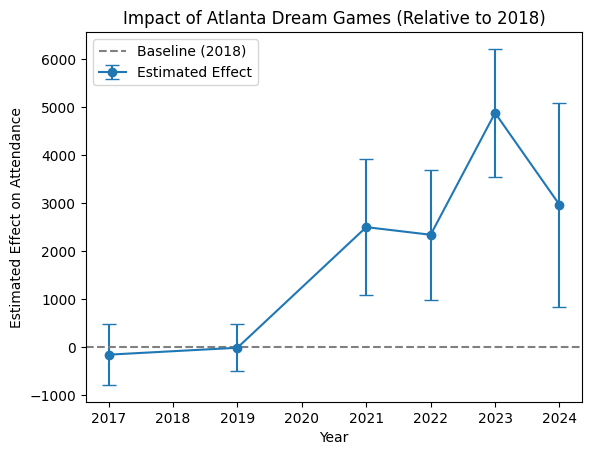

In [60]:
# Las Vegas Aces (A'ja Wilson; 2018-2024)
former_aces = ["Utah Starzz", "San Antonio Silver Stars", "San Antonio Stars", "Las Vegas Aces"]
lv_attendance_df = attendance_df.copy()

# 🚀 2. Create Treatment Variable for Aces Games (2018-2024)
lv_attendance_df['LV_Aces_Game'] = (
    lv_attendance_df['Home Team'].isin(former_aces) & lv_attendance_df['Year'].between(2017, 2024)
)

# 🚀 3. Create Interaction Terms for Each Year (Skip 2018 as the Reference; no data for 2020 (COVID year) so I will also omit it)
for year in [2017, 2019, 2021, 2022, 2023, 2024]:
    col_name = f'INX{year}'
    lv_attendance_df[col_name] = lv_attendance_df['LV_Aces_Game'].astype(int)
    lv_attendance_df.loc[lv_attendance_df['Year'] != year, col_name] = 0

# 🚀 4. Set Index for Panel Data (Team and Year)
lv_attendance_df = lv_attendance_df.set_index(['Home Team', 'Year'])

# 🚀 5. Define and Fit Panel Regression Model
mod = lm.PanelOLS.from_formula(
    'Attendance ~ INX2017 + INX2019 + INX2021 + INX2022 + INX2023 + INX2024 + EntityEffects + TimeEffects - TimeEffects[2018]',
    lv_attendance_df
)
clfe = mod.fit(cov_type='clustered', cluster_entity=True)
print(clfe.summary)

# 🚀 6. Extract Coefficients and Confidence Intervals
res = pd.concat([clfe.params, clfe.std_errors], axis=1)
res.columns = ['parameter', 'std_error']
res['ci'] = res['std_error'] * 1.96  # 95% CI
res['Year'] = [2017, 2019, 2021, 2022, 2023, 2024]  # Excluding 2018 as the reference

# Print results table
print("\n📊 Coefficients & Confidence Intervals:")
print(res)

# 🚀 7. Plot the Results
plt.errorbar(x=res['Year'], y=res['parameter'], yerr=res['ci'], fmt='o-', capsize=5, label="Estimated Effect")
plt.axhline(0, linestyle='dashed', color='gray', label="Baseline (2018)")
plt.xlabel("Year")
plt.ylabel("Estimated Effect on Attendance")
plt.title("Impact of Atlanta Dream Games (Relative to 2018)")
plt.legend()
plt.show()


                          PanelOLS Estimation Summary                           
Dep. Variable:             Attendance   R-squared:                        0.0077
Estimator:                   PanelOLS   R-squared (Between):              0.0119
No. Observations:                6214   R-squared (Within):               0.0075
Date:                Thu, Apr 10 2025   R-squared (Overall):              0.0086
Time:                        02:51:17   Log-likelihood                -5.787e+04
Cov. Estimator:             Clustered                                           
                                        F-statistic:                      9.5484
Entities:                          29   P-value                           0.0000
Avg Obs:                       214.28   Distribution:                  F(5,6154)
Min Obs:                       1.0000                                           
Max Obs:                       503.00   F-statistic (robust):             17.864
                            

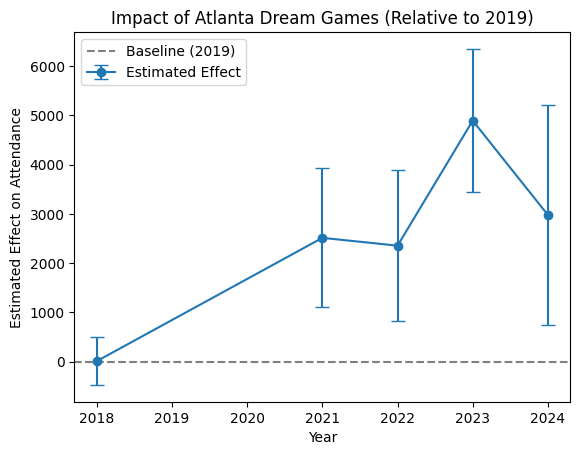

In [63]:
# Las Vegas Aces (Jackie Young; 2019-2024)
former_aces = ["Utah Starzz", "San Antonio Silver Stars", "San Antonio Stars", "Las Vegas Aces"]
lv_attendance_df = attendance_df.copy()

# 🚀 2. Create Treatment Variable for Aces Games (2019-2024)
lv_attendance_df['LV_Aces_Game'] = (
    lv_attendance_df['Home Team'].isin(former_aces) & lv_attendance_df['Year'].between(2018, 2024)
)

# 🚀 3. Create Interaction Terms for Each Year (Skip 2019 as the Reference; no data for 2020 (COVID year) so I will also omit it)
for year in [2018, 2021, 2022, 2023, 2024]:
    col_name = f'INX{year}'
    lv_attendance_df[col_name] = lv_attendance_df['LV_Aces_Game'].astype(int)
    lv_attendance_df.loc[lv_attendance_df['Year'] != year, col_name] = 0

# 🚀 4. Set Index for Panel Data (Team and Year)
lv_attendance_df = lv_attendance_df.set_index(['Home Team', 'Year'])

# 🚀 5. Define and Fit Panel Regression Model
mod = lm.PanelOLS.from_formula(
    'Attendance ~ INX2018 + INX2021 + INX2022 + INX2023 + INX2024 + EntityEffects + TimeEffects - TimeEffects[2019]',
    lv_attendance_df
)
clfe = mod.fit(cov_type='clustered', cluster_entity=True)
print(clfe.summary)

# 🚀 6. Extract Coefficients and Confidence Intervals
res = pd.concat([clfe.params, clfe.std_errors], axis=1)
res.columns = ['parameter', 'std_error']
res['ci'] = res['std_error'] * 1.96  # 95% CI
res['Year'] = [2018, 2021, 2022, 2023, 2024]  # Excluding 2019 as the reference

# Print results table
print("\n📊 Coefficients & Confidence Intervals:")
print(res)

# 🚀 7. Plot the Results
plt.errorbar(x=res['Year'], y=res['parameter'], yerr=res['ci'], fmt='o-', capsize=5, label="Estimated Effect")
plt.axhline(0, linestyle='dashed', color='gray', label="Baseline (2019)")
plt.xlabel("Year")
plt.ylabel("Estimated Effect on Attendance")
plt.title("Impact of Atlanta Dream Games (Relative to 2019)")
plt.legend()
plt.show()
